## LSTM
用LSTM在同样的数据集上训练并测试，与XGBoost和nyiso的预测对比

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn                                # nn 里是各种现成的网络层
from torch.utils.data import Dataset, DataLoader    # 负责取样本、分批

torch.manual_seed(42)        # 固定随机种子，让每次运行的结果尽量一致
print(torch.__version__)     # 应该是 2.14.1+cpu

2.14.1+cpu


### 1. 取整点、补齐时间网格

In [6]:
df = pd.read_csv('full_captial_21-25_features.csv', parse_dates=['timestamp'])
weather_cols = ['temperaturef', 'dewpointf', 'humidity', 'windspeedkmh']

# 只留整点的行，和之前对比 NYISO 时的做法一样
on_hour = df[(df.timestamp.dt.minute == 0) & (df.timestamp.dt.second == 0)]
hourly = on_hour.set_index('timestamp')[['load'] + weather_cols]
print(hourly.head())
print(len(hourly)) # 43651

                          load  temperaturef  dewpointf  humidity  \
timestamp                                                           
2021-01-01 00:00:00  1253.6528          25.0       19.9     80.66   
2021-01-01 01:00:00  1210.8152          25.0       19.9     80.66   
2021-01-01 02:00:00  1177.5476          23.0       18.0     80.85   
2021-01-01 03:00:00  1157.7712          23.0       19.0     84.39   
2021-01-01 04:00:00  1168.0000          19.9       18.0     92.19   

                     windspeedkmh  
timestamp                          
2021-01-01 00:00:00           9.3  
2021-01-01 01:00:00           9.3  
2021-01-01 02:00:00           7.4  
2021-01-01 03:00:00           5.6  
2021-01-01 04:00:00           5.6  
43651


In [7]:
# asfreq('1h') 把索引补成一小时一行的完整网格，原来没有的时刻填空值
hourly = hourly.asfreq('1h')
print(len(hourly))       # 43824 = 5 年的小时数
print(hourly.isna().sum())   # 每列 173 个空值

43824
load            173
temperaturef    173
dewpointf       173
humidity        173
windspeedkmh    173
dtype: int64


补齐的原因是LSTM 默认相邻两行正好差一小时。少了一行，后面所有行的「一周前」都会错位。XGBoost 没有这个问题，因为它不看行的顺序。
173 个空值的来源：5 个是每年夏令时拨快少掉的那一小时，另外 168 个是 2021-04-01 到 04-07 整整一周，原始数据里就没有。

In [8]:
# 按时间线性插值，把空值填上
hourly = hourly.interpolate(method='time')

# 48 小时前的负荷。网格已经是规整的，往下挪 48 行就是 48 小时前
hourly['load_lag48'] = hourly['load'].shift(48)

# 记下缺了一整周的那一段，步骤 3 切窗口时要避开
gap_start, gap_end = pd.Timestamp('2021-04-01'), pd.Timestamp('2021-04-08')

插值的局限：少一小时用前后平均补上没问题，但那一周是一条直线，是假数据。所以只用它把网格填满，训练时不让任何样本用到它。

### 2. 周期编码和标准化

In [9]:
idx = hourly.index

# 把小时、星期几、一年中的第几天变成圆上的一个点（sin 和 cos 两个坐标）。
hourly['hour_sin'] = np.sin(2 * np.pi * idx.hour /24)
hourly['hour_cos'] = np.cos(2 * np.pi * idx.hour / 24)
hourly['dow_sin'] = np.sin(2 * np.pi * idx.dayofweek / 7)
hourly['dow_cos'] = np.cos(2 * np.pi * idx.dayofweek / 7)
hourly['doy_sin'] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
hourly['doy_cos'] = np.cos(2 * np.pi * idx.dayofyear / 365.25)

# 编码的原因：23 点和 0 点只差一小时，但数字差 23。这和你在 03 里不放风向是同一个问题。

In [10]:
train_end = pd.Timestamp('2024-01-01')   # 这之前是训练集
val_end = pd.Timestamp('2025-01-01')     # 到这之前是验证集，之后是测试集
is_train = idx < train_end

# 均值和标准差只用训练集算，再用到全部数据上
load_mean = hourly.loc[is_train, 'load'].mean()
load_std = hourly.loc[is_train, 'load'].std()

scaled = hourly.copy()
scaled['load'] = (hourly['load'] - load_mean) / load_std
scaled['load_lag48'] = (hourly['load_lag48'] - load_mean) / load_std   # 和 load 用同一组均值方差
for c in weather_cols:
    m, s = hourly.loc[is_train, c].mean(), hourly.loc[is_train, c].std()
    scaled[c] = (hourly[c] - m) / s

feature_cols = ['load_lag48'] + weather_cols + \
    ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos']

X = scaled[feature_cols].values.astype('float32')   # 输入，形状 (43824, 11)
y = scaled['load'].values.astype('float32')         # 要预测的目标，形状 (43824,)
print(X.shape, y.shape)

(43824, 11) (43824,)


为什么要标准化：负荷在 1300 左右，湿度在 0–100，sin 在 ±1 之间。量级差太多时，梯度会被大数字的那一列主导，训练很慢或者不收敛。XGBoost 只比较大小，所以不需要这一步。
float32：PyTorch 默认用 32 位小数，pandas 默认 64 位，不转会报类型不匹配的错。

### 3. 切滑动窗口

In [11]:
SEQ_LEN = 168                       # 每个样本看过去 168 小时
pos = np.arange(len(hourly))        # 每一行的行号 0, 1, 2, ...

# 最早能当目标的行：前 48 行的 load_lag48 是空的，再往后要凑满 168 行的窗口
first_ok = 48 + SEQ_LEN - 1

# 窗口会碰到缺失那一周的目标时刻，全部排除
affected = (idx >= gap_start) & (idx < gap_end + pd.Timedelta(hours=48 + SEQ_LEN))

# 每个数组是一串行号，表示哪些时刻被当作预测目标。
train_idx = pos[(pos >= first_ok) & (idx < train_end) & ~affected]
val_idx = pos[(idx >= train_end) & (idx < val_end)]
test_idx = pos[idx >= val_end]
print(len(train_idx), len(val_idx), len(test_idx))   # 25681 8784 8760

25681 8784 8760


In [12]:
class WindowDataset(Dataset):
    def __init__(self, X, y, target_idx, seq_len):
        self.X = torch.from_numpy(X)      # NumPy 数组转成张量
        self.y = torch.from_numpy(y)
        self.target_idx = target_idx
        self.seq_len = seq_len

    # PyTorch 的约定，只要写出 __len__ 和 __getitem__ 两个方法，它就知道怎么取数据。
    def __len__(self):  # 一共有多少个样本
        return len(self.target_idx) # 样本数 = 目标时刻的个数

    def __getitem__(self, k):  # 取第 k 个样本
        i = self.target_idx[k]  # 目标时刻的行号
        # 输入是第 i-167 行到第 i 行，共 168 行；目标是第 i 行的负荷
        return self.X[i - self.seq_len + 1 : i + 1], self.y[i]


train_ds = WindowDataset(X, y, train_idx, SEQ_LEN)
val_ds = WindowDataset(X, y, val_idx, SEQ_LEN)
test_ds = WindowDataset(X, y, test_idx, SEQ_LEN)

xb, yb = train_ds[0]
print(xb.shape, yb.shape) # torch.Size([168, 11]) torch.Size([])

torch.Size([168, 11]) torch.Size([])


torch.Size([]) 为什么是空的？

它表示这是一个 0 维张量，也就是单个数字，里面是有值的。形状描述的是每一维有多长：

| 形状 | 含义 |
| --- | --- |
| `[]` | 一个数,没有维度 |
| `[256]` | 256 个数排成一列 |
| `[168, 11]` | 168 行 11 列的表 |
| `[256, 168, 11]` | 256 张这样的表 |

yb 是一个目标时刻的负荷，只有一个数，所以形状是 []。经过 DataLoader 把 256 个样本叠在一起后，它就变成 [256]。

为什么不提前切好：2.5 万个样本各 168 行，全部存下来要占很多内存。用到哪个现切哪个，几乎不占额外内存。
输入窗口包含第 i 行：第 i 行里放的是目标时刻的天气、日历和 48 小时前的负荷，没有目标时刻的负荷。feature_cols 里绝对不能出现 load，这是整个 notebook 最容易出错的地方.

In [13]:
# shuffle=True：打乱的是样本的先后顺序，每个样本内部的 168 小时仍然按时间排。训练时打乱能让每一批更有代表性；
# 验证和测试不打乱，预测结果才能和时间对上。
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1024, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=1024, shuffle=False)

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)    # torch.Size([256, 168, 11]) torch.Size([256])

torch.Size([256, 168, 11]) torch.Size([256])


DataLoader：把样本一批一批打包。输出形状是（256 个样本，168 个时间步，11 个特征），这个三维形状是所有序列模型的标准输入。
shuffle=True：打乱的是样本的先后顺序，每个样本内部的 168 小时仍然按时间排。训练时打乱能让每一批更有代表性；验证和测试不打乱，预测结果才能和时间对上。

### 4. LSTM Model

In [14]:
# nn.Module：所有模型的父类。__init__ 里声明有哪些层。
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden_size=64):
        super().__init__()
        # LSTM 层：每一步读入 11 个数，维护一个 64 维的隐藏状态,也就是模型的记忆容量。越大能记的越多，也越慢、越容易过拟合。
        # batch_first=True：告诉 LSTM 输入的第一维是 batch。不写的话它默认第一维是时间步，结果会全错而且不报错。
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size, batch_first=True)
        # 全连接层：把 64 个数变成 1 个数。
        self.head = nn.Linear(hidden_size, 1)

    # forward 里写数据怎么流过这些层。
    def forward(self, x):           # x 的形状 (batch, 168, 11)
        # out[:, -1, :]：LSTM 读完 168 步后，最后一步的隐藏状态就是对整周的总结，用它来预测。
        out, _ = self.lstm(x)       # out 的形状 (batch, 168, 64)，每个时间步一个隐藏状态
        last = out[:, -1, :]        # 只取最后一步的，形状 (batch, 64)
        return self.head(last).squeeze(-1) # (batch, 1) 压成 (batch,),让预测和 yb 形状相同。

model = LSTMModel(n_features=len(feature_cols))
print(model)
print(sum(p.numel() for p in model.parameters()))   # 19777 个参数
print(model(xb).shape)                               # torch.Size([256]).自动执行 forward。现在参数是随机的，输出的数没有意义，这一步只是检查形状。

LSTMModel(
  (lstm): LSTM(11, 64, batch_first=True)
  (head): Linear(in_features=64, out_features=1, bias=True)
)
19777
torch.Size([256])


### 5. 训练循环

In [15]:
loss_fn = nn.MSELoss()                          # 均方误差
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)       # 优化器，学习率 0.001

def evaluate(model, loader):
    model.eval()                                # 切到评估模式
    total, n = 0.0, 0
    with torch.no_grad():                       # 评估时不需要算梯度，省时间省内存
        # 「不算梯度」的意思是：梯度只在要更新参数时才用得上。验证时只想知道模型现在有多准，不打算根据验证集去改参数，所以不需要梯度
        for xb, yb in loader:
            pred = model(xb)                    # 形状 [1024] 的张量，这一批每个样本的预测值（标准化后的）
            total += loss_fn(pred,yb).item() * len(yb)   # 平均值乘以样本数，这一批的误差总和,.item()：把只含一个数的张量变成普通的 Python 数字。
            n += len(yb)
    return total / n                            # 所有样本的平均损失

print(evaluate(model, val_loader))              # 没训练
print(((X[val_idx, 0] - y[val_idx]) ** 2).mean()) # 朴素 baseline,直接拿 load_lag48 当预测

1.11146398341938
0.49199873


model.eval()和model.train()只是切换一个开关，告诉模型「现在是训练还是评估」，本身不做任何计算。有些层在两种模式下行为不同，最常见的是 dropout：训练时随机关掉一部分神经元防止过拟合，评估时全部打开。
目前的模型里只有 LSTM 和全连接层，没有这类层，所以这两行现在不影响结果。

In [16]:
EPOCHS = 2                             # 先跑 2 轮，确认能跑通；正式训练放到步骤 6
best_val, best_state = float('inf'), None

for epoch in range(1, EPOCHS + 1):
    model.train()                        # 切到训练模式
    total, n = 0.0, 0
    for xb, yb in train_loader:
        pred = model(xb)                # 1. 预测
        loss = loss_fn(pred, yb)        # 2. 算损失
        optimizer.zero_grad()           # 3. 把上一批留下的梯度清零
        loss.backward()                 # 4. 反向传播，算出每个参数的梯度
        optimizer.step()                # 5. 按梯度更新参数
        total += loss.item() * len(yb)
        n += len(yb)
    train_loss = total / n
    val_loss = evaluate(model, val_loader)

    # 验证集上更好，就把这时的参数存一份
    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    print(f'epoch {epoch}  train {train_loss:.4f}  val {val_loss:.4f}  '
          f'val RMSE {np.sqrt(val_loss) * load_std:.1f} MW')

epoch 1  train 0.4200  val 0.2334  val RMSE 113.2 MW
epoch 2  train 0.1336  val 0.1547  val RMSE 92.1 MW


中间那是所有 PyTorch 训练代码的核心，换任何模型都是这五行。
zero_grad()：PyTorch 的梯度默认是累加的，不清零的话这一批的梯度会和上一批的混在一起。
model.train() 和 model.eval()：有些层在训练和评估时行为不同。这个模型里没有这种层，但这是固定写法，以后加 dropout 就用得上。
best_state：训练轮数多了以后，训练损失会一直降，验证损失会先降后升，这就是过拟合。存下验证损失最低时的参数，最后用它做预测，这叫早停。
np.sqrt(val_loss) * load_std：把标准化后的均方误差换回兆瓦单位的 RMSE，方便和 XGBoost 的数字比。

### 6. 正式训练

#### 6.1 把训练循环包成函数，加上早停

In [20]:
def train_model(hidden_size, lr=1e-3, max_epochs=40, patience=5, seed=42):
    torch.manual_seed(seed)
    model = LSTMModel(n_features=len(feature_cols), hidden_size=hidden_size)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # best_val记录「到目前为止最低的验证损失」。float('inf')，正无穷，保证第一轮的 val_loss < best_val 一定成立
    best_val, best_state, bad_epochs = float('inf'), None, 0
    history = []                            # 记下每一轮的损失，后面画图用

    for epoch in range(1, max_epochs + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb in train_loader:
            pred = model(xb)
            loss = loss_fn(pred, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb)
            n += len(yb)
        train_loss = total / n
        val_loss = evaluate(model, val_loader)
        history.append({'epoch': epoch, 'train': train_loss, 'val': val_loss})

        if val_loss < best_val:          # 验证集变好：存参数，计数清零
            best_val, bad_epochs = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1             # 没变好：计数加一

        print(f'epoch {epoch:2d}  train {train_loss:.4f}  val {val_loss:.4f}  '
              f'val RMSE {np.sqrt(val_loss) * load_std:.1f} MW')

        if bad_epochs >= patience:      # 连续 5 轮没变好就停,验证损失会上下抖动，一轮没变好不代表以后不会变好，所以给 5 轮的耐心
            print(f'验证集连续 {patience} 轮没有变好，停止')
            break

    model.load_state_dict(best_state)  # 把参数恢复成验证集最好的那一轮
    return model, best_val, pd.DataFrame(history)

#### 6.2 试两种大小，用验证集选

In [21]:
# 手写循环调参
results = {}
for hidden in [32, 64]:
    print(f'===== hidden_size = {hidden}')
    model, best_val, history = train_model(hidden)
    results[hidden] = (model, best_val, history)
    print(f'最好的验证集 RMSE：{np.sqrt(best_val) * load_std:.1f} MW')

===== hidden_size = 32
epoch  1  train 0.4792  val 0.2648  val RMSE 120.6 MW
epoch  2  train 0.1569  val 0.1887  val RMSE 101.8 MW
epoch  3  train 0.1099  val 0.1602  val RMSE 93.8 MW
epoch  4  train 0.0892  val 0.1311  val RMSE 84.8 MW
epoch  5  train 0.0790  val 0.1275  val RMSE 83.7 MW
epoch  6  train 0.0724  val 0.1312  val RMSE 84.9 MW
epoch  7  train 0.0677  val 0.1160  val RMSE 79.8 MW
epoch  8  train 0.0643  val 0.1286  val RMSE 84.0 MW
epoch  9  train 0.0604  val 0.1189  val RMSE 80.8 MW
epoch 10  train 0.0574  val 0.1147  val RMSE 79.3 MW
epoch 11  train 0.0550  val 0.1406  val RMSE 87.9 MW
epoch 12  train 0.0544  val 0.1158  val RMSE 79.7 MW
epoch 13  train 0.0513  val 0.1190  val RMSE 80.8 MW
epoch 14  train 0.0510  val 0.1263  val RMSE 83.3 MW
epoch 15  train 0.0484  val 0.1184  val RMSE 80.6 MW
验证集连续 5 轮没有变好，停止
最好的验证集 RMSE：79.3 MW
===== hidden_size = 64
epoch  1  train 0.3893  val 0.2311  val RMSE 112.6 MW
epoch  2  train 0.1265  val 0.1442  val RMSE 89.0 MW
epoch  3  tra

#### 6.3 画损失曲线

Text(0, 0.5, 'MSE (standardized)')

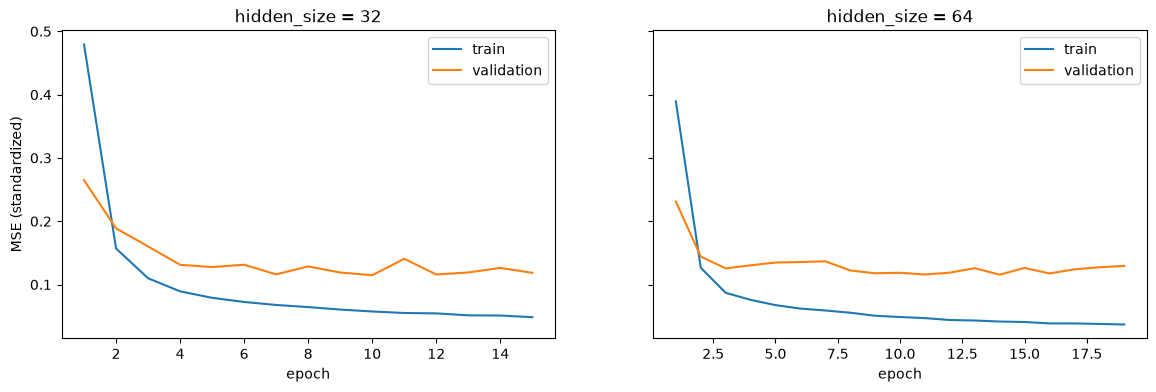

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, hidden in zip(axes, results):
    history = results[hidden][2]
    ax.plot(history['epoch'], history['train'], label='train')
    ax.plot(history['epoch'], history['val'], label='validation')
    ax.set_title(f'hidden_size = {hidden}')
    ax.set_xlabel('epoch')
    ax.legend()
axes[0].set_ylabel('MSE (standardized)')

训练线一直往下走，验证线降到 0.12 左右后来回抖动、不再下降。两条线之间越拉越大的差距就是过拟合。

#### 6.4 用 2021–2024 全部数据重新训练

In [24]:
# 选验证集上最好的配置，以及它最好的那一轮是第几轮
best_hidden = min(results, key=lambda h: results[h][1])
history = results[best_hidden][2]
best_epoch = int(history.loc[history['val'].idxmin(), 'epoch'])
print(best_hidden, best_epoch)

# 训练集和验证集合在一起
full_idx = np.concatenate([train_idx, val_idx])
full_loader = DataLoader(WindowDataset(X, y, full_idx, SEQ_LEN), batch_size=256, shuffle=True)

torch.manual_seed(42)
final_model = LSTMModel(n_features=len(feature_cols), hidden_size=best_hidden)
optimizer = torch.optim.Adam(final_model.parameters(), lr=1e-3)

for epoch in range(1, best_epoch + 1):       # 固定训练 best_epoch 轮,2024 年已经拿去训练了，没有验证集可以用来早停，只能沿用前面找到的轮数。
    final_model.train()
    total, n = 0.0, 0
    for xb, yb in full_loader:
        pred = final_model(xb)
        loss = loss_fn(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        n += len(yb)
    print(f'epoch {epoch:2d}  train {total / n:.4f}')

32 10
epoch  1  train 0.4151
epoch  2  train 0.1408
epoch  3  train 0.1020
epoch  4  train 0.0877
epoch  5  train 0.0809
epoch  6  train 0.0759
epoch  7  train 0.0715
epoch  8  train 0.0687
epoch  9  train 0.0659
epoch 10  train 0.0632


### 7. 预测与对比

#### 7.1 预测 2025 年，换回兆瓦

In [ ]:
def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:                 # 只要输入，目标用不上，用 _ 接住
            preds.append(model(xb))
    # torch.cat 把一批一批的预测接成一整条；再做标准化的逆运算
    # * load_std + load_mean：标准化是「减均值、除以标准差」，反过来就是「乘标准差、加均值」。
    return torch.cat(preds).numpy() * load_std + load_mean   # .numpy()：把张量变回 NumPy 数组，才能放进 pandas。

# idx[test_idx]：测试集每个目标对应的时间。test_loader 没有打乱，所以预测和时间是一一对上的。
lstm = pd.DataFrame({'timestamp': idx[test_idx], 'lstm': predict(final_model, test_loader)})
lstm.to_csv('pred_lstm_2025.csv', index=False)
print(lstm.head())

            timestamp         lstm
0 2025-01-01 00:00:00  1168.387864
1 2025-01-01 01:00:00  1120.788676
2 2025-01-01 02:00:00  1094.485560
3 2025-01-01 03:00:00  1086.593756
4 2025-01-01 04:00:00  1101.880391


#### 7.2 和 XGBoost、NYISO 放在同一批行上比

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# 和 04 一样的读法
xgb = pd.read_csv('pred_captial_2025.csv', parse_dates=['timestamp'])
xgb = xgb[(xgb.timestamp.dt.minute == 0) & (xgb.timestamp.dt.second == 0)]
fc = pd.read_csv('../data/nyiso_dayahead_forecasts/forecast_2025.csv', parse_dates=['timestamp'])
fc = fc[fc.zone == 'CAPITL'].drop_duplicates(subset=['timestamp'])

# 按时间合并顺便去掉了插值的行：2025 年夏令时那个不存在的小时，在 XGBoost 的文件里没有，合并时自动被丢掉。
cmp = xgb.merge(fc[['timestamp', 'forecast']], on='timestamp').merge(lstm, on='timestamp')
print(len(cmp))      # 8759，和 04 一样

def score_row(name, y_true, y_pred):
    return {'模型': name,
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred),
            'MAPE(%)': mean_absolute_percentage_error(y_true, y_pred) * 100}

rows = [score_row('LSTM', cmp['load'], cmp['lstm']),
        score_row('XGBoost', cmp['load'], cmp['prediction']),
        score_row('NYISO', cmp['load'], cmp['forecast']),
        score_row('朴素(t_m48)', cmp['load'], cmp['t_m48'])]
pd.DataFrame(rows).sort_values('RMSE')


8759


,模型,RMSE,MAE,R2,MAPE(%)
2,NYISO,93.379295,74.755797,0.878110,5.683190
1,XGBoost,95.216444,69.140878,0.873267,5.752057
0,LSTM,97.497749,69.712694,0.867122,5.817489
3,朴素(t_m48),190.769897,136.367662,0.491273,10.739509


#### 7.3 按月对比

,LSTM,XGBoost,NYISO
month,,,
1,3.67,4.21,6.10
2,4.58,4.39,6.18
3,6.51,7.08,6.69
4,6.88,7.49,5.77
5,6.76,7.55,6.90
6,8.88,6.52,5.42
7,5.98,5.46,5.03
8,5.47,5.74,5.17
9,6.23,5.83,4.61


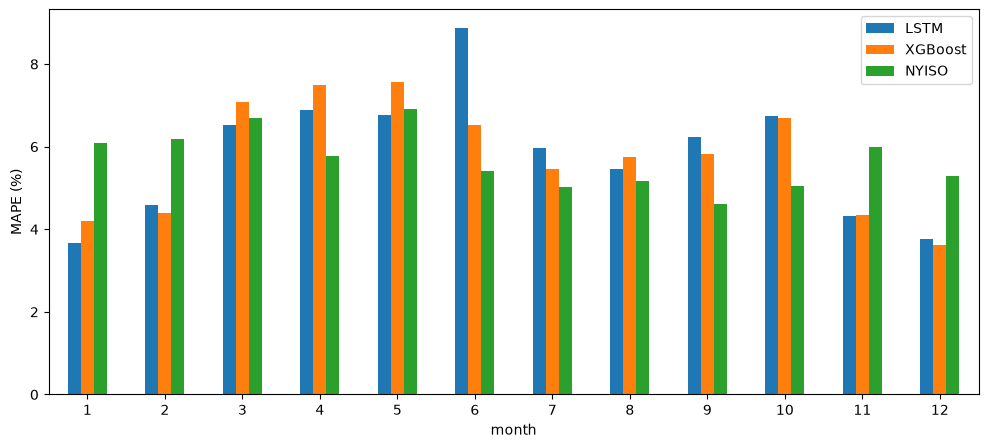

In [27]:
ape = pd.DataFrame({
    'LSTM': (cmp['load'] - cmp['lstm']).abs() / cmp['load'] * 100,
    'XGBoost': (cmp['load'] - cmp['prediction']).abs() / cmp['load'] * 100,
    'NYISO': (cmp['load'] - cmp['forecast']).abs() / cmp['load'] * 100,
})
monthly = ape.groupby(cmp.timestamp.dt.month).mean()
monthly.index.name = 'month'

ax = monthly.plot.bar(figsize=(12, 5), rot=0)
ax.set_ylabel('MAPE (%)')
monthly.round(2)

### 8. 总结

#### (1) 这个 notebook 做了什么

用和 XGBoost 相同的数据（Capital 区 2021–2024 年）训练一个 LSTM，预测 2025 年全年的整点负荷，再和 XGBoost、NYISO 官方预测放在同一批行上比较。

1. **数据**：从 `full_captial_21-25_features.csv` 里只取整点的行，补成一小时一行的完整网格，共 43824 行。缺的 173 行用线性插值填上，其中 168 行是 2021 年 4 月 1–7 日整周缺失，窗口会碰到这一周的 384 个时刻不当作训练目标。
2. **特征**：每小时 11 个数。48 小时前的负荷 `load_lag48`、4 个天气量（气温、露点、湿度、风速）、6 个时间量（小时、星期几、一年中第几天各用 sin 和 cos 表示）。负荷和天气量用训练集的均值、标准差做标准化。
3. **样本**：每个样本的输入是目标时刻往前 168 小时（含目标时刻）的 11 个特征，输出是目标时刻的负荷。
4. **信息对等**：输入里没有目标时刻的负荷，最近的负荷也是 48 小时前的，和 XGBoost 去掉 `t_m24` 的理由相同；天气同样用实测值。
5. **模型**：一层 LSTM 接一个全连接层，损失是均方误差，优化器是 Adam（学习率 0.001），每批 256 个样本。
6. **调参**：2021–2023 年训练（25681 个样本），2024 年验证（8784 个），比较 `hidden_size` 为 32 和 64 两种，验证损失连续 5 轮不下降就停。
7. **重训**：选出配置和轮数后，用 2021–2024 年全部 34465 个样本重新训练，再预测 2025 年（8760 个）。这样训练数据的年份和 XGBoost 一致。

#### (2) 结果

调参阶段（在 2024 年验证集上）：

| `hidden_size` | 停在第几轮 | 最好的一轮 | 验证集 RMSE |
|---|---|---|---|
| 32 | 15 | 第 10 轮 | **79.3** |
| 64 | 19 | 第 14 轮 | 79.6 |

选 `hidden_size=32`、训练 10 轮（约 5800 个参数）。

2025 年测试集（8759 个整点，和 04 是同一批行）：

| 模型 | RMSE | MAE | R² | MAPE |
|---|---|---|---|---|
| NYISO | **93.4** | 74.8 | **0.878** | **5.68%** |
| XGBoost | 95.2 | **69.1** | 0.873 | 5.75% |
| LSTM | 97.5 | 69.7 | 0.867 | 5.82% |
| 朴素（`t_m48`） | 190.8 | 136.4 | 0.491 | 10.74% |

RMSE 和 MAE 的单位是兆瓦。

#### (3) 结论

- **三者基本打平。** LSTM 的四个指标都略差于 XGBoost，但差距很小（RMSE 差 2.3 兆瓦，MAPE 差 0.07 个百分点），都远好于朴素 baseline。
- **LSTM 没有带来提升。** 在这种带天气和日历特征的负荷预测上，这是常见结果。XGBoost 训练只要几秒，不需要标准化和补齐时间网格，特征重要性也能直接看，所以这个任务上 XGBoost 更合适。
- **用上 2024 年的数据很重要。** 另行试验过：只用 2021–2023 年训练、不重训时，测试集 RMSE 是 106.5、MAPE 是 6.60%；加入 2024 年重训后降到 97.5 和 5.82%。
- **模型大小不是瓶颈。** `hidden_size` 从 32 加到 64，验证集 RMSE 几乎不变（79.3 对 79.6），训练时间却是三倍。
- **按月看，LSTM 和 XGBoost 各有胜负。** 1、3、4、5、8 月 LSTM 更准，2、6、7、9、10 月 XGBoost 更准，11、12 月几乎相同。LSTM 最差的是 6 月（8.9%，XGBoost 是 6.5%）。
- **和 NYISO 比，规律与 XGBoost 相同。** 冬季（1、2、11、12 月）LSTM 明显更准，4 月和 6–10 月 NYISO 更准。
- **整体偏差不大。** 另行统计过：LSTM 的预测全年平均比真实负荷高 20 兆瓦，XGBoost 高 8 兆瓦，NYISO 低 43 兆瓦。

#### (4) 读这些数字时要注意的地方

- **只跑了一个随机种子。** 神经网络的初始参数和每批样本的顺序都是随机的，换一个种子，RMSE 浮动几兆瓦是正常的。97.5 和 95.2 的差距在这个范围内，不能据此说哪个模型更好。
- **只调了一个参数。** 窗口长度、学习率、层数、dropout 都没有调，XGBoost 那边则搜索了 12 组参数。LSTM 还有提升空间，但不确定有多大。
- **验证集比测试集好看很多。** 2024 年验证集 RMSE 是 79，2025 年测试集是 97。XGBoost 也有同样的现象（交叉验证 84.8，测试 95.2），说明 2025 年本身更难预测。
- **重训后的模型没有验证集。** 最终模型的训练轮数是沿用调参阶段找到的 10 轮，训练数据多了一年，最合适的轮数可能略有不同。
- **LSTM 少用了几个特征。** 没有放气压和降水，也没有 `t_m168`、`temp_24h`、`temp_72h`，因为 168 小时的窗口里已经包含了这些信息。
- **用的是实测气温。** 和 03、04 一样，这对 NYISO 不公平，它做预测时只能用天气预报。

#### (5) 可以继续做的事

- 用 3–5 个随机种子各训练一次，报告平均值和波动范围，或者把几次的预测取平均。
- 调窗口长度（比如 72、336 小时）和学习率，加 dropout。
- 一次输出未来 24 小时的负荷，而不是每次只预测一个时刻，更接近真实的提前一天预测。
- 把 LSTM 和 XGBoost 的预测取平均。两者在不同月份各有优势，平均后可能比任何一个都好。
- 重点看 6 月：LSTM 在这个月明显变差，可以画出那几周的曲线找原因。